# Decision Tree Predicting the attrition of your valuable employees.

## Dataset

Link : https://drive.google.com/file/d/1bm3Ujm51ehD-ZXZUZhdNnY_NXQ-HgvXZ/view?usp=drive_link

## Import Library

In [4]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.tree import export_text, plot_tree
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_style("whitegrid")
plt.style.use("fivethirtyeight")

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [7]:
df = pd.read_csv("/content/drive/MyDrive/SI DATA SCIENTIST CAKAP/electricityConsumptionAndProductioction.csv")
df.head()

,DateTime,Consumption,Production,Nuclear,Wind,Hydroelectric,Oil and Gas,Coal,Solar,Biomass
0,2019-01-01 00:00:00,6352,6527,1395,79,1383,1896,1744,0,30
1,2019-01-01 01:00:00,6116,5701,1393,96,1112,1429,1641,0,30
2,2019-01-01 02:00:00,5873,5676,1393,142,1030,1465,1616,0,30
3,2019-01-01 03:00:00,5682,5603,1397,191,972,1455,1558,0,30
4,2019-01-01 04:00:00,5557,5454,1393,159,960,1454,1458,0,30


## Data Understanding

In [8]:
df.shape

(46011, 10)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 46011 entries, 0 to 46010
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   DateTime       46011 non-null  object
 1   Consumption    46011 non-null  int64 
 2   Production     46011 non-null  int64 
 3   Nuclear        46011 non-null  int64 
 4   Wind           46011 non-null  int64 
 5   Hydroelectric  46011 non-null  int64 
 6   Oil and Gas    46011 non-null  int64 
 7   Coal           46011 non-null  int64 
 8   Solar          46011 non-null  int64 
 9   Biomass        46011 non-null  int64 
dtypes: int64(9), object(1)
memory usage: 3.5+ MB


In [10]:
df.describe()

,Consumption,Production,Nuclear,Wind,Hydroelectric,Oil and Gas,Coal,Solar,Biomass
count,46011.000000,46011.000000,46011.000000,46011.000000,46011.000000,46011.000000,46011.000000,46011.000000,46011.000000
mean,6587.616440,6518.645628,1291.177501,792.310882,1857.052444,1171.890418,1193.157332,156.688031,55.851862
std,1043.654923,986.805018,236.549637,675.812712,692.592157,434.748917,320.449368,229.502650,14.235554
min,3889.000000,3315.000000,562.000000,-26.000000,175.000000,198.000000,279.000000,0.000000,17.000000
25%,5773.000000,5814.000000,1347.000000,236.000000,1347.000000,858.000000,962.000000,0.000000,45.000000
50%,6552.000000,6462.000000,1383.000000,592.000000,1747.000000,1211.000000,1172.000000,2.000000,57.000000
75%,7321.000000,7176.000000,1405.000000,1205.000000,2265.000000,1511.000000,1406.000000,280.000000,67.000000
max,9615.000000,9886.000000,1457.000000,2811.000000,4434.000000,2141.000000,2537.000000,1137.000000,89.000000


In [11]:
is_null = df.isnull().sum()
print(is_null)

DateTime         0
Consumption      0
Production       0
Nuclear          0
Wind             0
Hydroelectric    0
Oil and Gas      0
Coal             0
Solar            0
Biomass          0
dtype: int64


In [12]:
df.dropna(inplace=True)

In [13]:
# Menampilkan jumlah nilai hilang setelah dibersihkan
print("\nSetelah dibersihkan:")
print(df.isnull().sum())


Setelah dibersihkan:
DateTime         0
Consumption      0
Production       0
Nuclear          0
Wind             0
Hydroelectric    0
Oil and Gas      0
Coal             0
Solar            0
Biomass          0
dtype: int64


## EDA

<Axes: xlabel='Consumption', ylabel='count'>

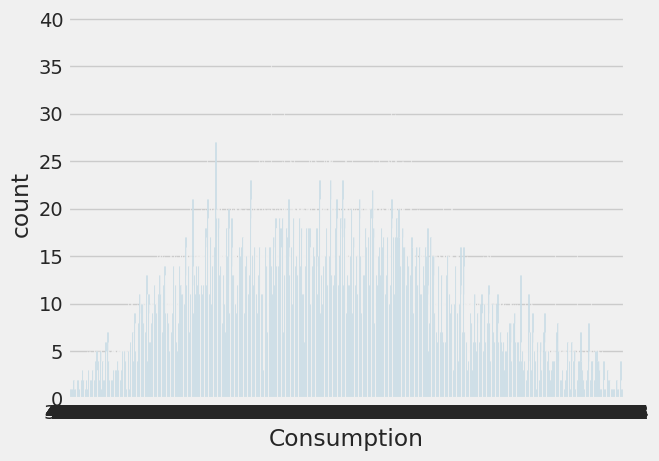

In [14]:
sns.countplot(x='Consumption', data=df)

In [15]:
df.drop(['DateTime'], axis='columns', inplace=True)
categorical_col = []

for column in df.columns:
    if df[column].dtype == 'object' and len(df[column].unique()) <= 50:
        categorical_col.append(column)

df['Consumption'] = df['Consumption'].astype("category").cat.codes

## Data Processing

In [16]:
# Transform categorical data into dummies
# categorical_col.remove("Consumption")
# data = pd.get_dummies(df, columns=categorical_col)
# data.info()
from sklearn.preprocessing import LabelEncoder

label = LabelEncoder()
for column in categorical_col:
    # Check if the column still needs encoding
    if df[column].dtype == 'object':
        df[column] = label.fit_transform(df[column])

## Modelling

In [17]:
from sklearn.model_selection import train_test_split

# Memisahkan fitur dan target
X = df.drop('Consumption', axis=1)  # Fitur
y = df['Consumption']  # Target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [18]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

def print_score(clf, X_train, y_train, X_test, y_test, train=True):
    if train:
        pred = clf.predict(X_train)
        clf_report = pd.DataFrame(classification_report(y_train, pred, output_dict=True))
        print("Train Result:\n================================================")
        print(f"Accuracy Score: {accuracy_score(y_train, pred) * 100:.2f}%")
        print("_______________________________________________")
        print(f"CLASSIFICATION REPORT:\n{clf_report}")
        print("_______________________________________________")
        print(f"Confusion Matrix: \n {confusion_matrix(y_train, pred)}\n")

    elif train==False:
        pred = clf.predict(X_test)
        clf_report = pd.DataFrame(classification_report(y_test, pred, output_dict=True))
        print("Test Result:\n================================================")
        print(f"Accuracy Score: {accuracy_score(y_test, pred) * 100:.2f}%")
        print("_______________________________________________")
        print(f"CLASSIFICATION REPORT:\n{clf_report}")
        print("_______________________________________________")
        print(f"Confusion Matrix: \n {confusion_matrix(y_test, pred)}\n")

In [19]:
from sklearn.tree import DecisionTreeClassifier

tree_clf = DecisionTreeClassifier(random_state=42)
tree_clf.fit(X_train, y_train)

print_score(tree_clf, X_train, y_train, X_test, y_test, train=True)
print_score(tree_clf, X_train, y_train, X_test, y_test, train=False)

Train Result:
Accuracy Score: 99.99%
_______________________________________________
CLASSIFICATION REPORT:
             1    2    3    4    5    6    7    8    9   10  ...  4871  4872  \
precision  1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0  ...   1.0   1.0   
recall     1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0  ...   1.0   1.0   
f1-score   1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0  ...   1.0   1.0   
support    1.0  1.0  1.0  2.0  1.0  1.0  1.0  1.0  1.0  1.0  ...   1.0   1.0   

           4873  4874  4875  4876  4880  accuracy     macro avg  weighted avg  
precision   1.0   1.0   1.0   1.0   1.0  0.999918      0.999892      0.999933  
recall      1.0   1.0   1.0   1.0   1.0  0.999918      0.999889      0.999918  
f1-score    1.0   1.0   1.0   1.0   1.0  0.999918      0.999875      0.999918  
support     1.0   1.0   1.0   1.0   1.0  0.999918  36808.000000  36808.000000  

[4 rows x 4777 columns]
_______________________________________________
Confusion Matrix: 

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_

Test Result:
Accuracy Score: 1.48%
_______________________________________________
CLASSIFICATION REPORT:
             0    2   10   12   16   17   21   22   26   32  ...  4867  4868  \
precision  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  ...   0.0   0.0   
recall     0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  ...   0.0   0.0   
f1-score   0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  ...   0.0   0.0   
support    1.0  0.0  0.0  1.0  1.0  1.0  1.0  1.0  1.0  0.0  ...   1.0   1.0   

           4870  4876  4877  4878  4879  accuracy    macro avg  weighted avg  
precision   0.0   0.0   0.0   0.0   0.0  0.014778     0.010621      0.017699  
recall      0.0   0.0   0.0   0.0   0.0  0.014778     0.010520      0.014778  
f1-score    0.0   0.0   0.0   0.0   0.0  0.014778     0.009617      0.014773  
support     1.0   0.0   1.0   1.0   1.0  0.014778  9203.000000   9203.000000  

[4 rows x 4300 columns]
_______________________________________________
Confusion Matrix: 
 [[0 0

In [ ]:
# Decision tree hyperparameter

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

params = {
    "criterion":("gini", "entropy"),
    "splitter":("best", "random"),
    "max_depth":(list(range(1, 20))),
    "min_samples_split":[2, 3, 4],
    "min_samples_leaf":list(range(1, 20)),
}


tree_clf = DecisionTreeClassifier(random_state=42)
tree_cv = GridSearchCV(
    tree_clf,
    params,
    scoring="f1",
    n_jobs=-1,
    verbose=1,
    cv=5
)

tree_cv.fit(X_train, y_train)
best_params = tree_cv.best_params_
print(f"Best paramters: {best_params})")

tree_clf = DecisionTreeClassifier(**best_params)
tree_clf.fit(X_train, y_train)
print_score(tree_clf, X_train, y_train, X_test, y_test, train=True)
print_score(tree_clf, X_train, y_train, X_test, y_test, train=False)

In [1]:
from IPython.display import Image
from six import StringIO
from sklearn.tree import export_graphviz
import pydot

features = list(df.columns)
features.remove("Consumption")

NameError: name 'df' is not defined

In [ ]:
dot_data = StringIO()
export_graphviz(tree_clf, out_file=dot_data, feature_names=features, filled=True)
graph = pydot.graph_from_dot_data(dot_data.getvalue())
Image(graph[0].create_png())

## RANDOM FOREST

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [21]:
import numpy as np
import cv2
import glob
import os
import matplotlib.pyplot as plt
import string
from mlxtend.plotting import plot_decision_regions
from mpl_toolkits.mplot3d import Axes3D
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.utils.multiclass import unique_labels
from sklearn import metrics
from sklearn.svm import SVC

In [22]:
df_visceral= pd.read_csv('/content/drive/MyDrive/SI DATA SCIENTIST CAKAP/electricityConsumptionAndProductioction.csv')
df_visceral.head()

,DateTime,Consumption,Production,Nuclear,Wind,Hydroelectric,Oil and Gas,Coal,Solar,Biomass
0,2019-01-01 00:00:00,6352,6527,1395,79,1383,1896,1744,0,30
1,2019-01-01 01:00:00,6116,5701,1393,96,1112,1429,1641,0,30
2,2019-01-01 02:00:00,5873,5676,1393,142,1030,1465,1616,0,30
3,2019-01-01 03:00:00,5682,5603,1397,191,972,1455,1558,0,30
4,2019-01-01 04:00:00,5557,5454,1393,159,960,1454,1458,0,30


## Deskripsi Dataset

In [23]:
#Melihat list variabel dari dataset
list(df_visceral)

['DateTime',
 'Consumption',
 'Production',
 'Nuclear',
 'Wind',
 'Hydroelectric',
 'Oil and Gas',
 'Coal',
 'Solar',
 'Biomass']

In [24]:
df_visceral.dtypes

,0
DateTime,object
Consumption,int64
Production,int64
Nuclear,int64
Wind,int64
Hydroelectric,int64
Oil and Gas,int64
Coal,int64
Solar,int64
Biomass,int64


In [29]:
# Check existing columns
print(df_visceral.columns)

Index(['DateTime', 'Consumption', 'Production', 'Nuclear', 'Wind',
       'Hydroelectric', 'Oil and Gas', 'Coal', 'Solar', 'Biomass'],
      dtype='object')


In [30]:
# Drop the 'number' column, ignoring errors if it doesn't exist
df_visceral = df_visceral.drop('number', axis=1, errors='ignore')

# Clean and convert the 'DateTime' column
df_visceral['DateTime'] = df_visceral['DateTime'].str.replace(',', '.')
df_visceral['DateTime'] = pd.to_numeric(df_visceral['DateTime'], errors='coerce')

AttributeError: Can only use .str accessor with string values!

In [ ]:
df_visceral.head()

Mengetahui informasi dari dataset yang diantaranya yaitu jumlah missing values dan tipe data pada masing-masing kolom atau variabel

In [ ]:
df_visceral.info(verbose=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 46011 entries, 0 to 46010
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Consumption    46011 non-null  int64
 1   Production     46011 non-null  int64
 2   Nuclear        46011 non-null  int64
 3   Wind           46011 non-null  int64
 4   Hydroelectric  46011 non-null  int64
 5   Oil and Gas    46011 non-null  int64
 6   Coal           46011 non-null  int64
 7   Solar          46011 non-null  int64
 8   Biomass        46011 non-null  int64
dtypes: int64(9)
memory usage: 3.2 MB


## Data Preparation

## Missing Value Chacking & Handling

In [ ]:
#Missing Value Checking
print(df_visceral.isnull().sum())

In [ ]:
#Deskripsi Dataset
df_visceral.describe()

Library missingno digunakan untuk visualisasi missing value yang terdapat pada dataset. Tak hanya berbentuk bar chart, tetapi bisa juga dalam bentuk matrix ataupun heatmap

In [ ]:
#Missing Value Checking Menggunakan Library Missingno
import missingno as msno
msno.bar(df_visceral, color='teal')

In [ ]:
df_visceral_copy=df_visceral.copy()

In [ ]:
df_visceral_copy.dtypes

Mengisi missing value dengan mode, median, dan mean

In [ ]:
df_visceral_copy['ethnicity'].fillna(df_visceral_copy['ethnicity'].mode(), inplace = True)
df_visceral_copy['pregnancies (number)'].fillna(df_visceral_copy['pregnancies (number)'].median(), inplace = True)
df_visceral_copy['first fasting glucose (mg/dl)'].fillna(df_visceral_copy['first fasting glucose (mg/dl)'].mean(), inplace = True)
df_visceral_copy['bmi pregestational (kg/m)'].fillna(df_visceral_copy['bmi pregestational (kg/m)'].mean(), inplace = True)